In [3]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [6]:
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Використовується пристрій: {device}")

Використовується пристрій: cpu


In [8]:
data_dir = "./chest_xray/chest_xray"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes  # ['NORMAL', 'PNEUMONIA']
print(f"Класи: {class_names}")
print(f"Зображень у Train: {len(train_dataset)}, у Test: {len(test_dataset)}")

Класи: ['NORMAL', 'PNEUMONIA']
Зображень у Train: 5216, у Test: 624


In [9]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.0001)

num_epochs = 5
print("\nПочаток навчання...")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward(  )
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Епоха [{epoch + 1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\jimmi/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.2MB/s]



Початок навчання...
Епоха [1/5] | Loss: 0.4404 | Acc: 0.7872
Епоха [2/5] | Loss: 0.3286 | Acc: 0.8702
Епоха [3/5] | Loss: 0.2776 | Acc: 0.8970
Епоха [4/5] | Loss: 0.2552 | Acc: 0.9053
Епоха [5/5] | Loss: 0.2312 | Acc: 0.9116



Результати на тестовій вибірці:
Accuracy:  0.8958
Precision: 0.8916
Recall:    0.9487
F1-Score:  0.9193


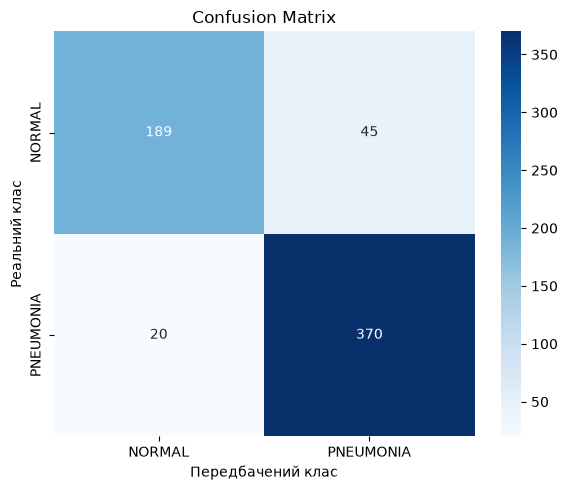

Модель успішно збережена у pneumonia_resnet18.pth


In [10]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, pos_label=1)
rec = recall_score(all_labels, all_preds, pos_label=1)
f1 = f1_score(all_labels, all_preds, pos_label=1)

print("\nРезультати на тестовій вибірці:")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Передбачений клас')
plt.ylabel('Реальний клас')
plt.tight_layout()
plt.show()

model_save_path = "pneumonia_resnet18.pth"
torch.save(model.state_dict(), model_save_path)
print(f"Модель успішно збережена у {model_save_path}")

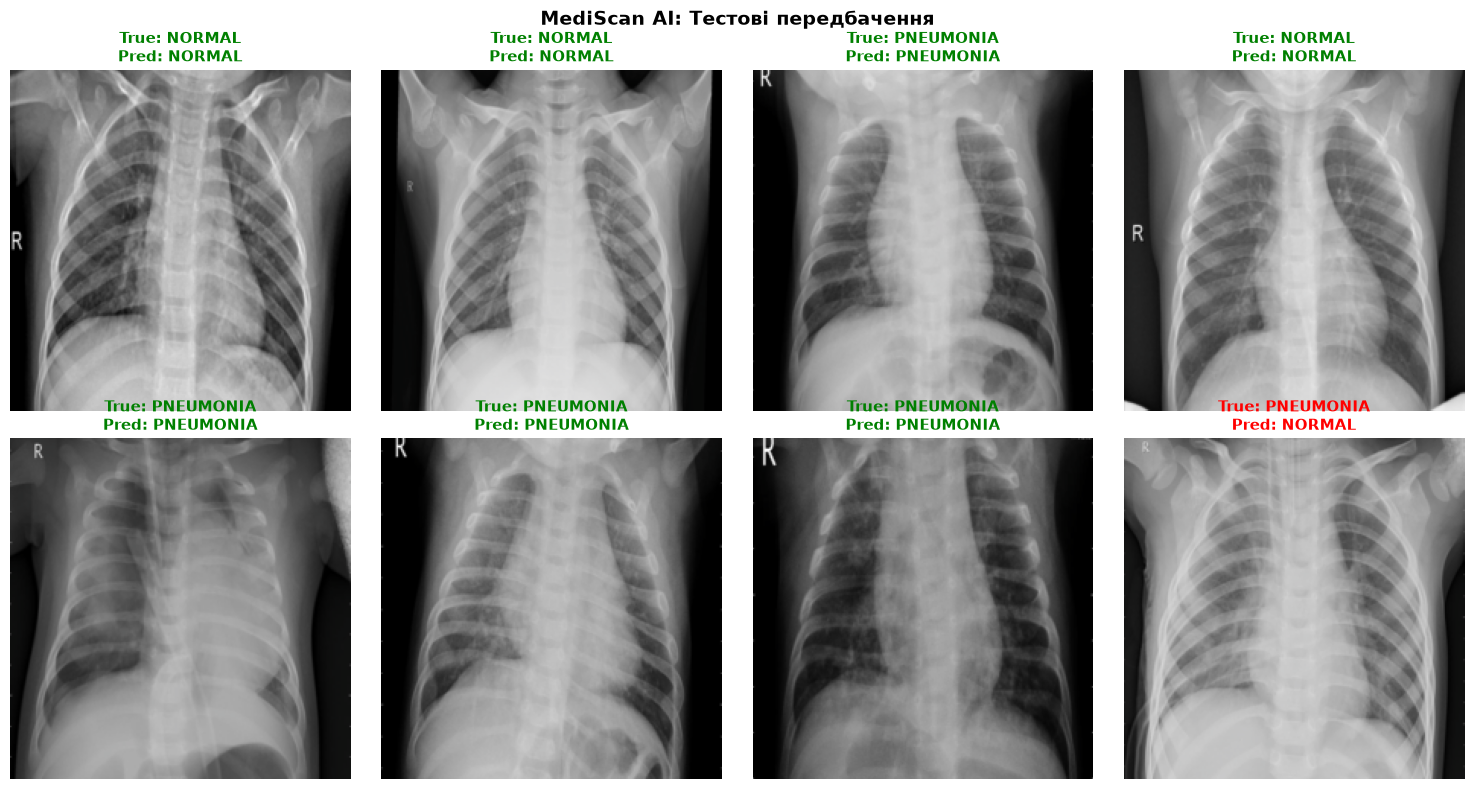

Графік збережено як pneumonia_predictions.png


In [13]:
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = tensor.numpy().transpose((1, 2, 0))
    inp = std * inp + mean
    return np.clip(inp, 0, 1)

indices = np.random.choice(len(test_dataset), size=8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

model.eval()
with torch.no_grad():
    for i, idx in enumerate(indices):
        img_tensor, true_label = test_dataset[idx]
        input_tensor = img_tensor.unsqueeze(0).to(device)

        output = model(input_tensor)
        _, pred = torch.max(output, 1)
        pred_label = pred.item()

        ax = axes[i]
        ax.imshow(denormalize(img_tensor))
        ax.axis('off')

        color = 'green' if pred_label == true_label else 'red'
        title = f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}"
        ax.set_title(title, color=color, fontsize=11, fontweight='bold')

plt.suptitle("MediScan AI: Тестові передбачення", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("pneumonia_predictions.png", dpi=300)
plt.show()
print("Графік збережено як pneumonia_predictions.png")